# Analysera filmrecensioner

In [1]:
import pandas as pd
import numpy as np
import src.preprocessing as prep
import src.log_reg as lr
import src.evaluation as eval
import src.distilbert_model as dbm

## Exploratory Data Analysis

In [2]:
train_df, test_df = prep.load_imdb_data_as_dataframe()

In [3]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    25000 non-null  str  
 1   label   25000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 32.0 MB


In [4]:
train_df["label"].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

In [5]:
pd.set_option('display.max_colwidth', None)
train_df.head()

,text,label
0,"I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered ""controversial"" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, even then it's not shot like some cheaply made porno. While my countrymen mind find it shocking, in reality sex and nudity are a major staple in Swedish cinema. Even Ingmar Bergman, arguably their answer to good old boy John Ford, had sex scenes in his films.<br /><br />I do commend the filmmakers for the fact that any sex shown in the film is shown for artistic purposes rather than just to shock people and make money to be shown in pornographic theaters in America. I AM CURIOUS-YELLOW is a good film for anyone wanting to study the meat and potatoes (no pun intended) of Swedish cinema. But really, this film doesn't have much of a plot.",0
1,"""I Am Curious: Yellow"" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity. Granted, they only offer some fleeting views, but where are the R-rated films with gaping vulvas and flapping labia? Nowhere, because they don't exist. The same goes for those crappy cable shows: schlongs swinging in the breeze but not a clitoris in sight. And those pretentious indie movies like The Brown Bunny, in which we're treated to the site of Vincent Gallo's throbbing johnson, but not a trace of pink visible on Chloe Sevigny. Before crying (or implying) ""double-standard"" in matters of nudity, the mentally obtuse should take into account one unavoidably obvious anatomical difference between men and women: there are no genitals on display when actresses appears nude, and the same cannot be said for a man. In fact, you generally won't see female genitals in an American film in anything short of porn or explicit erotica. This alleged double-standard is less a double standard than an admittedly depressing ability to come to terms culturally with the insides of women's bodies.",0
2,"If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no cogent story.<br /><br />One might feel virtuous for sitting thru it because it touches on so many IMPORTANT issues but it does so without any discernable motive. The viewer comes away with no new perspectives (unless one comes up with one while one's mind wanders, as it will invariably do during this pointless film).<br /><br />One might better spend one's time staring out a window at a tree growing.<br /><br />",0
3,"This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead.<br /><br />The film has two strong elements and those are, (1) the realistic acting (2) the impressive, undeservedly good, photo. Apart from that, what strikes me most is the endless stream of silliness. Lena Nyman has to be most annoying actress in the world. She acts so stupid and with all the nudity in this film,...it's unattractive. Comparing to Godard's film, intellectuality has been r

In [6]:
# Antal ord per recension
train_df["word_count"] = train_df["text"].str.split().str.len()

train_df["word_count"].describe()

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: word_count, dtype: float64

In [7]:
import re

rating_pattern = r"\b(10|[1-9])\s*(/|out of)\s*10\b"

train_ratings = train_df[
    train_df["text"].str.contains(rating_pattern, case=False, regex=True, na=False)
]

print("Antal recensioner med uttryckligt betyg:", len(train_ratings))

Antal recensioner med uttryckligt betyg: 2105


C:\Users\nadin\AppData\Local\Temp\ipykernel_21188\3904672014.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  train_df["text"].str.contains(rating_pattern, case=False, regex=True, na=False)


In [8]:
print("POSITIVA:")
for text in train_ratings[train_ratings["label"] == 1]["text"].head(3):
    print(text)
    print("\n" + "-"*80 + "\n")

print("NEGATIVA:")
for text in train_ratings[train_ratings["label"] == 0]["text"].head(3):
    print(text)
    print("\n" + "-"*80 + "\n")

POSITIVA:
That was the first thing that sprang to mind as I watched the closing credits to Europa make there was across the screen, never in my entire life have I seen a film of such technical genius, the visuals of Europa are so impressive that any film I watch in it's wake will only pale in comparison, forget your Michael Bay, Ridley Scott slick Hollywood cinematography, Europa has more ethereal beauty than anything those two could conjure up in a million years. Now I'd be the first to hail Lars von Trier a genius just off the back of his films Breaking the Waves and Dancer in the Dark, but this is stupid, the fact that Europa has gone un-noticed by film experts for so long is a crime against cinema, whilst overrated rubbish like Crouching Tiger, Hidden Dragon and Life is Beautiful clean up at the academy awards (but what do the know) Europa has been hidden away, absent form video stores and (until recently) any British TV channels. <br /><br />The visuals in Europa are not MTV gloss

In [9]:
common_text = set(train_df["text"]) & set(test_df["text"])
print("Reviews in both train and test sets:", len(common_text))

Reviews in both train and test sets: 123


## Logistic Regression

In [11]:
X_train, X_val, X_test, y_train, y_val, y_test = prep.prepare_data_for_logreg(train_df, test_df)
tfidf, X_train_tfidf, X_val_tfidf, X_test_tfidf = lr.vectorize_text(X_train, X_val, X_test)

model = lr.train_logistic_regression(X_train_tfidf, y_train)
y_val_pred = model.predict(X_val_tfidf)
y_val_proba = model.predict_proba(X_val_tfidf)

In [12]:
val_results_lr = eval.calculate_metrics(y_val, y_val_pred)
print("Validation results:")
for metric, value in val_results_lr.items():
  print(f"{metric.capitalize()}: {value:.4f}")

Validation results:
Accuracy: 0.8854
Precision: 0.8770
Recall: 0.8950
F1: 0.8859


### Logistic Regression: utvärdering på testdata

In [13]:
# Predict on test data
y_test_pred = model.predict(X_test_tfidf)
y_test_proba = model.predict_proba(X_test_tfidf)

# Evaluate test results
test_results_lr = eval.calculate_metrics(y_test, y_test_pred)

print("Test results:")
for metric, value in test_results_lr.items():
    print(f"{metric.capitalize()}: {value:.4f}")

Test results:
Accuracy: 0.8809
Precision: 0.8797
Recall: 0.8833
F1: 0.8815


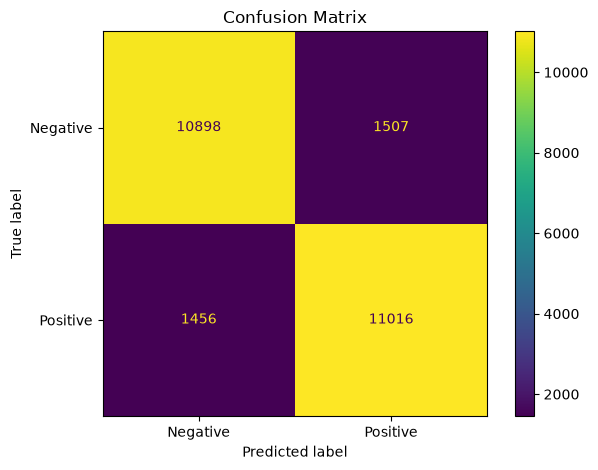

In [14]:
confusion_matrix_lr_test = eval.create_confusion_matrix(y_test, y_test_pred)

In [15]:
classification_report_test = eval.classification_report(y_test, y_test_pred)
print(classification_report_test)

              precision    recall  f1-score   support

           0       0.88      0.88      0.88     12405
           1       0.88      0.88      0.88     12472

    accuracy                           0.88     24877
   macro avg       0.88      0.88      0.88     24877
weighted avg       0.88      0.88      0.88     24877



In [16]:
prediction_errors_test = eval.get_prediction_errors(y_test, y_test_pred, X_test, y_test_proba)

display(prediction_errors_test.head(8))

,text,actual,predicted,prob_negative,prob_positive
11997,"this movie was pure genius. john waters is brilliant. it is hilarious and i am not sick of it even after seeing it about 20 times since i bought it a few months ago. the acting is great, although ricki lake could have been better. and johnny depp is magnificent. he is such a beautiful man and a very talented actor. and seeing most of johnny's movies, this is probably my favorite. i give it 9.5/10. rent it today!",0,1,2.67,97.33
4067,this is definitely one of the best kung fu movies in the history of cinema. the screenplay is really well done (which is not often the case for this type of movies) and you can see that chuck (in one of his first role)is a great actor. the final fight with the sherif deputy in the bullring is a masterpiece!,0,1,2.75,97.25
14979,"when the movie first started i thought cheesy. the first ten minutes were really boring. after the slow beginning and some of the soap opera antics, i started liking it. the plot was different than anything i had ever seen. now, was it a horror? not really. it shouldn't have been classied as a horror or the producers should have put more money into the movie to make it scary. as it was, the creatures where only there for a short time. i can only assume this was for money reason. the good side was that the movie was very entertaining. it held my interest (after the start) and did make me wonder about creatures from another dimension. it was obvious that this was a first time movie for the director, but there were a couple of highlights. by the end, i was hooked. too bad hollywood didn't put more money behind this.",1,0,97.16,2.84
17773,"my sisters and my cousin(female) forced me to see this chick movie. its not the kind of movie i would prefer to see, but it really wasn't that bad. i wouldn't want to see this movie, but after watching it i couldn't say it was bad, just not my kind of film. it was very accurate in acting out what woman really talk about and do in certain situations. as a guy, i wasn't too amused by the jokes, but man the women sure were. they related to the movie and yeah it was funny to see themselves on the big screen. ""oh em gee i do that to haha"" i've never seen the original, nor would i care to. if you are a girl, this is a must see, but maybe girls would say this movie sucked, probably. i don't see a 13 year old going, ""wow i remember going threw that when i was 30."" no man would have this in there collection, but i can't say it was horrible, so meh.",1,0,96.67,3.33
15113,"**spoilers ahead** it is really unfortunate that a movie so well produced turns out to be such a disappointment. i thought this was full of (silly) clichés and that it basically tried to hard. to the (american) guys out there: how many of you spend your time jumping on your girlfriend's bed and making monkey sounds? to the (married) girls: how many of you have suddenly gone from prudes to nymphos overnight--but not with your husband? to the french: would you really ask about someone being ""à la fac"" when you know they don't speak french? wouldn't you use a more common word like ""université""? i lived in france for a while and i sort of do know and understand europe (and i love it), but my (german) roommate and i found this pretty insulting overall. it looked like a movie funded by the european parliament, and it tried too hard basically. it had all sorts of differences that it tried to tie together (not a bad thing in itself) but the result is at best awkward, but in fact ridiculous--too many clashes that wouldn't really happen. then the end of the movie--the last 10 minutes--ruined all the rest. why doesn't xavier talk to the erasmus students he meets back in paris? why does he just walk off? why does he just run away from his job, is that ""freedom""? and in the end, is the new europe supposed to rest on a bunch of people who smoke up and shag all day? is this what it's made up of? besides, the acting was pretty horrib

## DistilBERT

In [17]:
train_dataset, val_dataset, test_dataset = prep.prepare_data_for_distilbert()

sampled_split = train_dataset.train_test_split(
    train_size=5000, seed=42, stratify_by_column="label"
)
small_train_dataset = sampled_split["train"]

tokenized_train, tokenized_val, tokenized_test, tokenizer = dbm.tokenize_datasets(small_train_dataset, val_dataset, test_dataset)

model, data_collator = dbm.get_model_and_collator(tokenizer)

trainer = dbm.setup_trainer(model, tokenized_train, tokenized_val, data_collator)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [18]:
trainer.train()

c:\Users\nadin\Documents\projekt_ds\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.408253,0.264496,0.896600


TrainOutput(global_step=157, training_loss=0.3642789391195698, metrics={'train_runtime': 11263.6082, 'train_samples_per_second': 0.444, 'train_steps_per_second': 0.014, 'total_flos': 661881636597120.0, 'train_loss': 0.3642789391195698, 'epoch': 1.0})

### DistilBERT: utvärdering på testdata

In [19]:
test_results = trainer.predict(tokenized_test)

y_true_db = test_results.label_ids
y_pred_db = np.argmax(test_results.predictions, axis=1)

test_metrics = eval.calculate_metrics(y_true_db, y_pred_db)
print("Test Metrics for DistilBERT:")
for metric, value in test_metrics.items():
  print(f"{metric.capitalize()}: {value:.4f}")


c:\Users\nadin\Documents\projekt_ds\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Test Metrics for DistilBERT:
Accuracy: 0.8970
Precision: 0.8960
Recall: 0.8989
F1: 0.8975


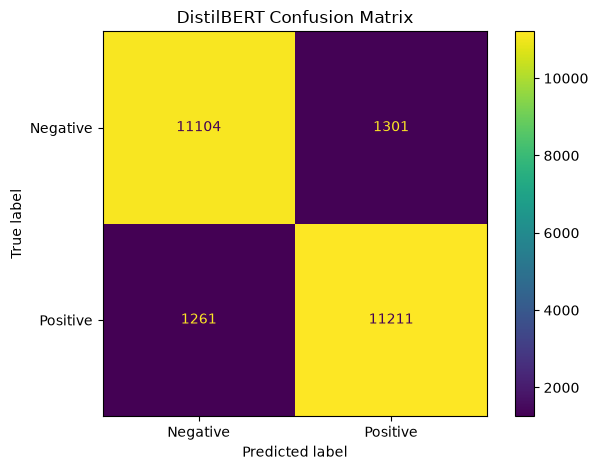

array([[11104,  1301],
       [ 1261, 11211]])

In [20]:
eval.create_confusion_matrix(y_true_db, y_pred_db, title="DistilBERT Confusion Matrix")

In [21]:
from scipy.special import softmax

y_proba_db = softmax(test_results.predictions, axis=1)

errors_db = eval.get_prediction_errors(
    y_true_db, y_pred_db, test_dataset["text"], y_proba_db
)
display(errors_db.head(8))

text  \
9483                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    Lois Weber's film "Hypocrites" was and still kind of is a very bold and daring film. I enjoyed it and was very impressed by the filming and story of it. The priest sees the hypocrisy of the people in his church and tries to show them the "naked" truth. The people are appalled when he reveals the naked statue portraying truth, after failing to lead them to it and the few that did, help along the way. The people do not want to face the truth that they are doing anything wrong, but it shows them putting things before God, going to beach parties acting inappropriate, their materialistic ways, and other things in which the people of our world do that tend to not be morally right. In the end, failing to gain any followers, he must enter into the gates of heaven alone. This film seems to me to be very bold, in the fact that a naked woman is shown throughout it, especially considering the time period in which this film was made. The imagery and symbolism portrayed in this movie I found incredible. The way they made the naked woman translucent and using a naked woman to symbolize the naked truth shows a lot of creativity and art. Showing the different sins of the people as they walked down the road and refused to follow along the path, each with different excuses, setbacks, and/or higher priorities, was a great way of representing the people of today. This film does a very good job of getting the moral message across to its audience. Lois Weber has a tremendous way of capturing her specta

## Jämförelse Logistic Regression och DistilBERT

In [22]:
comparison = pd.DataFrame({
    "Logistic Regression": test_results_lr,
    "DistilBERT": test_metrics
})

display(comparison.round(4))

,Logistic Regression,DistilBERT
accuracy,0.8809,0.8970
precision,0.8797,0.8960
recall,0.8833,0.8989
f1,0.8815,0.8975


# Demo: Testa modellen med en ny filmrecenssion

In [24]:
review = input("Write a movie review in English:")

cleaned_review = prep.clean_text(review)

review_tfidf = tfidf.transform([cleaned_review])

prediction = model.predict(review_tfidf)[0]
probabilities = model.predict_proba(review_tfidf)[0]

if prediction == 1:
    print("\nPrediction: Positive review")
else:
    print("\nPrediction: Negative review")

print(f"Confidence: {probabilities[prediction]:.1%}")

AttributeError: 'DistilBertForSequenceClassification' object has no attribute 'predict'